<a href="https://colab.research.google.com/github/Hackathon-Group-F/Hackathon/blob/main/Hackathon_Group_F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Hackathon Group F

### Step 1: Data Exploration

In [14]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, log_loss
from sklearn.svm import SVC
import zipfile
from google.colab import files

In [2]:
# Loading Dataset
# Direct raw GitHub URLs
base_url = "https://raw.githubusercontent.com/Hackathon-Group-F/Hackathon/main/"

train = pd.read_csv(base_url + "dataset_A_training.csv")
test = pd.read_csv(base_url + "dataset_A_testing.csv")
example_sub = pd.read_csv(base_url + "dataset_A_example_submission.csv")

# Quick verification check
print("Successfully loaded datasets!")
print(f"Training set:   {train.shape[0]} rows, {train.shape[1]} columns")
print(f"Testing set:    {test.shape[0]} rows, {test.shape[1]} columns")
print(f"Example sub:    {example_sub.shape[0]} rows, {example_sub.shape[1]} columns")

# Inspect
train.head()

Successfully loaded datasets!
Training set:   4756 rows, 31 columns
Testing set:    4749 rows, 30 columns
Example sub:    4749 rows, 2 columns


,respondent_id,flu_concern,flu_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,seasonal_vaccine
0,1,2.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Employed,Non-MSA,0.0,0.0,entertainment,0,0
1,2,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,Rent,Employed,"MSA, Principle City",1.0,0.0,education,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,...,"> $75,000",Married,Own,Not in Labor Force,"MSA, Not Principle City",1.0,0.0,NaN,0,0
3,4,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",1.0,2.0,utilities,0,1
4,5,2.0,2.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,...,Below Poverty,Not Married,Rent,Not in Labor Force,"MSA, Not Principle City",2.0,0.0,NaN,1,0


In [3]:
print("="*60)
print("1. TARGET CLASS DISTRIBUTION")
print("="*60)
target_counts = train['seasonal_vaccine'].value_counts()
target_pct = (train['seasonal_vaccine'].value_counts(normalize=True) * 100).round(2)
target_summary = pd.DataFrame({'Count': target_counts, 'Percentage (%)': target_pct})
print(target_summary)

print("\n" + "="*60)
print("2. MISSING VALUES COMPARISON (TRAIN vs TEST)")
print("="*60)
missing_train = train.isnull().sum()
missing_train_pct = (missing_train / len(train) * 100).round(2)
missing_test = test.isnull().sum()
missing_test_pct = (missing_test / len(test) * 100).round(2)

missing_df = pd.DataFrame({
    'Train Missing': missing_train,
    'Train %': missing_train_pct,
    'Test Missing': missing_test,
    'Test %': missing_test_pct
}).dropna(subset=['Train Missing'])

print(missing_df[missing_df['Train %'] > 0].sort_values(by='Train %', ascending=False))

print("\n" + "="*60)
print("3. CLINICAL RISK PROFILE (Drivers for $18,500 Hospitalisation Cost)")
print("="*60)
print("\nAge Group Breakdown:")
print(train.groupby('age_group')['seasonal_vaccine'].agg(['count', 'mean']).rename(columns={'mean': 'Vax_Rate'}))

print("\nChronic Conditions Breakdown:")
print(train.groupby('number_chronic_med_conditions')['seasonal_vaccine'].agg(['count', 'mean']).rename(columns={'mean': 'Vax_Rate'}))

1. TARGET CLASS DISTRIBUTION
                  Count  Percentage (%)
seasonal_vaccine                       
1                  2551           53.64
0                  2205           46.36

2. MISSING VALUES COMPARISON (TRAIN vs TEST)
                             Train Missing  Train %  Test Missing  Test %
employment_sector                     2314    48.65        2405.0   50.64
health_insurance                      1925    40.48        1982.0   41.74
income_poverty                         790    16.61         797.0   16.78
rent_or_own                            381     8.01         379.0    7.98
doctor_recc_seasonal                   321     6.75         345.0    7.26
education                              270     5.68         269.0    5.66
employment_status                      269     5.66         277.0    5.83
marital_status                         265     5.57         269.0    5.66
child_under_6_months                   152     3.20         155.0    3.26
health_worker            

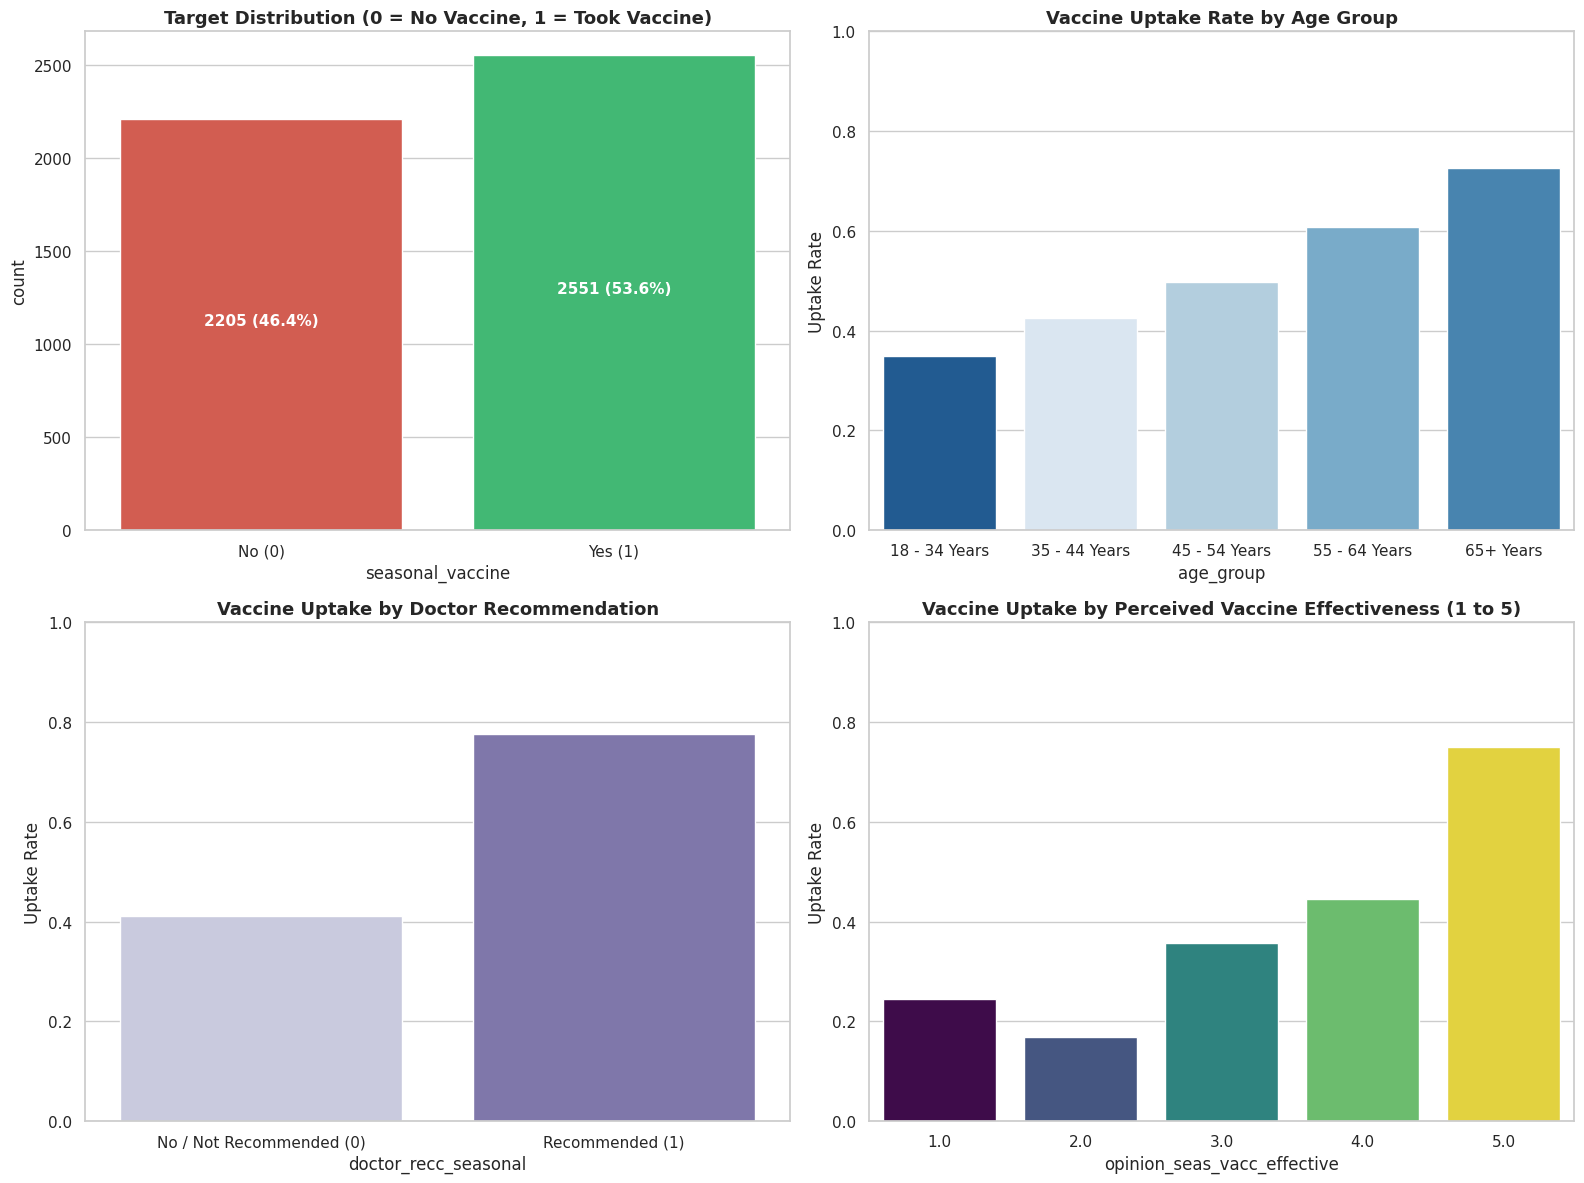

In [4]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Target Distribution
sns.countplot(x='seasonal_vaccine', hue='seasonal_vaccine', data=train, ax=axes[0, 0], palette=['#e74c3c', '#2ecc71'], legend=False)
axes[0, 0].set_title('Target Distribution (0 = No Vaccine, 1 = Took Vaccine)', fontsize=13, fontweight='bold')
axes[0, 0].set_xticks([0, 1])
axes[0, 0].set_xticklabels(['No (0)', 'Yes (1)'])
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f'{int(p.get_height())} ({p.get_height()/len(train)*100:.1f}%)',
                        (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                        ha='center', color='white', fontweight='bold', fontsize=11)

# 2. Vaccine Uptake by Age Group
age_order = ['18 - 34 Years', '35 - 44 Years', '45 - 54 Years', '55 - 64 Years', '65+ Years']
sns.barplot(x='age_group', y='seasonal_vaccine', hue='age_group', data=train, order=age_order, ax=axes[0, 1], palette='Blues_r', errorbar=None, legend=False)
axes[0, 1].set_title('Vaccine Uptake Rate by Age Group', fontsize=13, fontweight='bold')
axes[0, 1].set_ylabel('Uptake Rate')
axes[0, 1].set_ylim(0, 1)

# 3. Doctor Recommendation Impact
sns.barplot(x='doctor_recc_seasonal', y='seasonal_vaccine', hue='doctor_recc_seasonal', data=train, ax=axes[1, 0], palette='Purples', errorbar=None, legend=False)
axes[1, 0].set_title('Vaccine Uptake by Doctor Recommendation', fontsize=13, fontweight='bold')
axes[1, 0].set_xticks([0, 1])
axes[1, 0].set_xticklabels(['No / Not Recommended (0)', 'Recommended (1)'])
axes[1, 0].set_ylabel('Uptake Rate')
axes[1, 0].set_ylim(0, 1)

# 4. Perceived Vaccine Effectiveness vs Uptake
sns.barplot(x='opinion_seas_vacc_effective', y='seasonal_vaccine', hue='opinion_seas_vacc_effective', data=train, ax=axes[1, 1], palette='viridis', errorbar=None, legend=False)
axes[1, 1].set_title('Vaccine Uptake by Perceived Vaccine Effectiveness (1 to 5)', fontsize=13, fontweight='bold')
axes[1, 1].set_ylabel('Uptake Rate')
axes[1, 1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

### Step 2: Pre-processing

In [5]:
# -------------------------------------------------------------
# 1. SEPARATE TARGET AND IDENTIFIERS
# -------------------------------------------------------------
# Extract target vector and IDs
y_train = train['seasonal_vaccine'].astype(int)
train_ids = train['respondent_id']
test_ids = test['respondent_id']

# Feature matrices (exclude IDs and target)
X_train = train.drop(columns=['respondent_id', 'seasonal_vaccine']).copy()
X_test = test.drop(columns=['respondent_id']).copy()

# -------------------------------------------------------------
# 2. DEFINE FEATURE GROUPS
# -------------------------------------------------------------
cat_cols = [
    'age_group', 'education', 'race', 'sex', 'income_poverty',
    'marital_status', 'rent_or_own', 'employment_status',
    'census_msa', 'employment_sector'
]

binary_cols = [
    'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask',
    'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home',
    'behavioral_touch_face', 'doctor_recc_seasonal', 'child_under_6_months',
    'health_worker', 'health_insurance'
]

ordinal_cols = [
    'flu_concern', 'flu_knowledge', 'opinion_seas_vacc_effective',
    'opinion_seas_risk', 'opinion_seas_sick_from_vacc'
]

count_cols = [
    'household_adults', 'household_children', 'number_chronic_med_conditions'
]

# -------------------------------------------------------------
# 3. IMPUTE MISSING VALUES (FIT ON TRAIN, TRANSFORM ON TEST)
# -------------------------------------------------------------
# A. Categoricals: label missing values as a distinct category ('Missing')
for col in cat_cols:
    X_train[col] = X_train[col].fillna('Missing').astype(str)
    X_test[col] = X_test[col].fillna('Missing').astype(str)

# B. Binary features: fill missing values with 0.0 (absence of condition/action)
for col in binary_cols:
    X_train[col] = X_train[col].fillna(0.0).astype(float)
    X_test[col] = X_test[col].fillna(0.0).astype(float)

# C. Ordinal ratings: fill missing values with median from the training set
for col in ordinal_cols:
    med_val = X_train[col].median()
    X_train[col] = X_train[col].fillna(med_val).astype(float)
    X_test[col] = X_test[col].fillna(med_val).astype(float)

# D. Count features: fill missing values with mode from the training set
for col in count_cols:
    mode_val = X_train[col].mode()[0]
    X_train[col] = X_train[col].fillna(mode_val).astype(float)
    X_test[col] = X_test[col].fillna(mode_val).astype(float)

# -------------------------------------------------------------
# 4. ONE-HOT ENCODING & FEATURE ALIGNMENT
# -------------------------------------------------------------
X_train_encoded = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)

# Ensure train and test share exact identical columns in identical order
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

# Convert all boolean dummy indicators to integers (0/1)
X_train_encoded = X_train_encoded.astype(float)
X_test_encoded = X_test_encoded.astype(float)

# -------------------------------------------------------------
# 5. SANITY CHECK & VALIDATION
# -------------------------------------------------------------
print("="*60)
print("PRE-PROCESSING VALIDATION")
print("="*60)
print(f"X_train shape: {X_train_encoded.shape} (rows, features)")
print(f"X_test shape:  {X_test_encoded.shape} (rows, features)")
print(f"y_train rows:  {len(y_train)}")
print(f"Remaining nulls in X_train: {X_train_encoded.isnull().sum().sum()}")
print(f"Remaining nulls in X_test:  {X_test_encoded.isnull().sum().sum()}")
print("Pre-processing successfully finished!")

PRE-PROCESSING VALIDATION
X_train shape: (4756, 64) (rows, features)
X_test shape:  (4749, 64) (rows, features)
y_train rows:  4756
Remaining nulls in X_train: 0
Remaining nulls in X_test:  0
Pre-processing successfully finished!


### Step 3: Modelling

In [6]:
# -------------------------------------------------------------
# 1. DEFINE FINE-TUNED CANDIDATE MODEL POOL (10 CONFIGURATIONS)
# -------------------------------------------------------------
from sklearn.svm import SVC

candidate_models = {
    # Linear Models (varying L2 regularization strength C)
    'LogReg (C=0.1, L2)': make_pipeline(
        StandardScaler(), LogisticRegression(C=0.1, penalty='l2', max_iter=1000, random_state=42)
    ),
    'LogReg (C=1.0, L2)': make_pipeline(
        StandardScaler(), LogisticRegression(C=1.0, penalty='l2', max_iter=1000, random_state=42)
    ),

    # Support Vector Machine (RBF Kernel with Platt Scaling)
    'SVM (RBF, C=1.0)': make_pipeline(
        StandardScaler(), SVC(C=1.0, kernel='rbf', probability=True, random_state=42)
    ),

    # Bagging Ensembles (varying tree depth and leaf regularization)
    'Random Forest (depth=10)': RandomForestClassifier(
        n_estimators=300, max_depth=10, min_samples_leaf=5, random_state=42, n_jobs=-1
    ),
    'Random Forest (depth=15)': RandomForestClassifier(
        n_estimators=400, max_depth=15, min_samples_leaf=3, random_state=42, n_jobs=-1
    ),
    'Extra Trees (depth=12)': ExtraTreesClassifier(
        n_estimators=300, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=-1
    ),

    # Boosting Ensembles (varying learning rate, depth, and L2 regularization)
    'GradBoost (lr=0.05, d=3)': GradientBoostingClassifier(
        n_estimators=250, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=42
    ),
    'GradBoost (lr=0.03, d=4)': GradientBoostingClassifier(
        n_estimators=250, learning_rate=0.03, max_depth=4, subsample=0.8, random_state=42
    ),
    'HistGradBoost (lr=0.03, d=5)': HistGradientBoostingClassifier(
        max_iter=250, learning_rate=0.03, max_depth=5, l2_regularization=2.0, random_state=42
    ),

    # Neural Network (Multi-Layer Perceptron with L2 alpha penalty)
    'MLP Net (64, 32)': make_pipeline(
        StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), alpha=0.1, max_iter=300, early_stopping=True, random_state=42)
    )
}

# -------------------------------------------------------------
# 2. TRAIN POOL ACROSS 5-FOLD STRATIFIED CROSS-VALIDATION
# -------------------------------------------------------------
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_preds = {name: np.zeros(len(y_train)) for name in candidate_models}
test_preds = {name: np.zeros(len(X_test_encoded)) for name in candidate_models}
results_list = []

print("="*78)
print("TRAINING & TUNING CANDIDATE MODEL POOL (5-FOLD STRATIFIED CV)")
print("="*78)

for name, model in candidate_models.items():
    for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_encoded, y_train)):
        X_tr, y_tr = X_train_encoded.iloc[train_idx], y_train.iloc[train_idx]
        X_val, y_val = X_train_encoded.iloc[val_idx], y_train.iloc[val_idx]

        model.fit(X_tr, y_tr)
        oof_preds[name][val_idx] = model.predict_proba(X_val)[:, 1]
        test_preds[name] += model.predict_proba(X_test_encoded)[:, 1] / skf.n_splits

    probs = oof_preds[name]
    preds_bin = (probs >= 0.5).astype(int)

    auc = roc_auc_score(y_train, probs)
    acc = accuracy_score(y_train, preds_bin)
    f1 = f1_score(y_train, preds_bin)
    loss = log_loss(y_train, probs)

    results_list.append({
        'Model': name,
        'ROC-AUC': round(auc, 4),
        'Accuracy': round(acc, 4),
        'F1-Score': round(f1, 4),
        'Log-Loss': round(loss, 4)
    })
    print(f"✓ {name:<28} | ROC-AUC: {auc:.4f} | Acc: {acc:.4f} | LogLoss: {loss:.4f}")

# -------------------------------------------------------------
# 3. DYNAMICALLY BLEND TOP 3 & SELECT OVERALL TOP 5 MODELS
# -------------------------------------------------------------
standalone_df = pd.DataFrame(results_list).sort_values(by='ROC-AUC', ascending=False)
top_3_names = standalone_df.head(3)['Model'].tolist()

ens_name = 'Ensemble (Top 3 Tuned Blend)'
oof_preds[ens_name] = np.mean([oof_preds[m] for m in top_3_names], axis=0)
test_preds[ens_name] = np.mean([test_preds[m] for m in top_3_names], axis=0)

ens_probs = oof_preds[ens_name]
ens_bin = (ens_probs >= 0.5).astype(int)

results_list.append({
    'Model': ens_name,
    'ROC-AUC': round(roc_auc_score(y_train, ens_probs), 4),
    'Accuracy': round(accuracy_score(y_train, ens_bin), 4),
    'F1-Score': round(f1_score(y_train, ens_bin), 4),
    'Log-Loss': round(log_loss(y_train, ens_probs), 4)
})

# Sort full pool and extract Top 5
leaderboard_df = pd.DataFrame(results_list).sort_values(by='ROC-AUC', ascending=False).reset_index(drop=True)
leaderboard_df.index = leaderboard_df.index + 1  # Rank 1 to 11print("\n" + "="*78)

print("FULL CANDIDATE POOL LEADERBOARD (SORTED BY ROC-AUC)")
print("="*78)
print(leaderboard_df.to_string())
print("="*78)
print("All 11 models trained! Passing all models to Step 4 for Town Cost Evaluation.")

TRAINING & TUNING CANDIDATE MODEL POOL (5-FOLD STRATIFIED CV)
✓ LogReg (C=0.1, L2)           | ROC-AUC: 0.8493 | Acc: 0.7767 | LogLoss: 0.4844
✓ LogReg (C=1.0, L2)           | ROC-AUC: 0.8493 | Acc: 0.7763 | LogLoss: 0.4848
✓ SVM (RBF, C=1.0)             | ROC-AUC: 0.8404 | Acc: 0.7675 | LogLoss: 0.4939
✓ Random Forest (depth=10)     | ROC-AUC: 0.8459 | Acc: 0.7675 | LogLoss: 0.5036
✓ Random Forest (depth=15)     | ROC-AUC: 0.8462 | Acc: 0.7691 | LogLoss: 0.4965
✓ Extra Trees (depth=12)       | ROC-AUC: 0.8425 | Acc: 0.7687 | LogLoss: 0.5075
✓ GradBoost (lr=0.05, d=3)     | ROC-AUC: 0.8531 | Acc: 0.7782 | LogLoss: 0.4761
✓ GradBoost (lr=0.03, d=4)     | ROC-AUC: 0.8514 | Acc: 0.7754 | LogLoss: 0.4782
✓ HistGradBoost (lr=0.03, d=5) | ROC-AUC: 0.8482 | Acc: 0.7696 | LogLoss: 0.4828
✓ MLP Net (64, 32)             | ROC-AUC: 0.8374 | Acc: 0.7660 | LogLoss: 0.5007
FULL CANDIDATE POOL LEADERBOARD (SORTED BY ROC-AUC)
                           Model  ROC-AUC  Accuracy  F1-Score  Log-Loss
1   

### Step 4: Performance Analysis

CLINICAL RISK FACTORS & HOSPITALISATION PROBABILITIES (100% Infection Assumed)
    Age Group  Chronic Conditions Prob (Unvaccinated) Prob (Vaccinated)
18 - 34 Years                   0                0.6%              0.3%
45 - 54 Years                   1                3.5%             1.75%
    65+ Years                   0                9.5%             4.75%
    65+ Years                   2               17.1%             8.55%

Per-person thresholds (train): min 0.116 | mean 0.515 | max 0.844

STEP 4: ALL 11 MODELS RANKED BY LOWEST TOTAL TOWN COST ($) — PER-PERSON THRESHOLDS
                           Model Best Threshold Min Total Cost ($) Vaccine Cost ($) Hospital Cost ($)  Expected Hosp Cost @ 0.50 ($) Cost @ best global th ($) Savings vs 0.50 ($)
1   Ensemble (Top 3 Tuned Blend)     per-person         $3,892,501         $931,200        $2,961,301         160.07      $3,960,714                $3,944,474             $68,214
2       GradBoost (lr=0.05, d=3)     per-person     

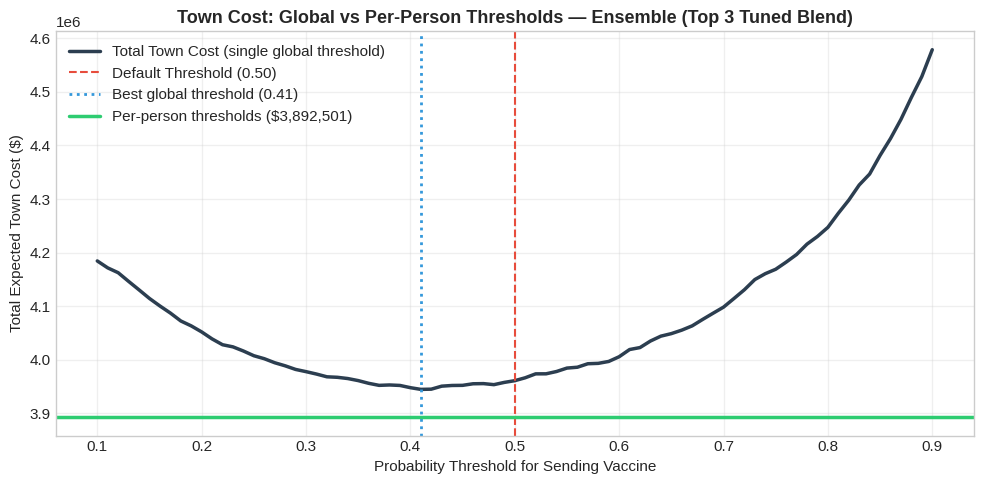

In [16]:
# -------------------------------------------------------------
# 1. DEFINE HOSPITALISATION PROBABILITY MODEL
# -------------------------------------------------------------
# Baseline 100% infection probability assumed across the town
BASE_HOSP_RISK_BY_AGE = {
    '18 - 34 Years': 0.006,  # 0.6% base risk if infected
    '35 - 44 Years': 0.012,  # 1.2% base risk if infected
    '45 - 54 Years': 0.025,  # 2.5% base risk if infected
    '55 - 64 Years': 0.045,  # 4.5% base risk if infected
    '65+ Years': 0.095       # 9.5% base risk if infected
}
VACCINE_COST = 300.0
HOSP_COST = 18500.0

def estimate_hospitalisation_prob(age_group_series, chronic_cond_series, is_vaccinated):
    """
    Computes individual hospitalisation probability based on:
    1. Age group (0.6% to 9.5% base risk)
    2. Number of chronic medical conditions (+40% risk per condition, max 3.5x)
    3. Vaccination status (50% risk reduction if successfully vaccinated)
    """
    base_risk = age_group_series.map(BASE_HOSP_RISK_BY_AGE).fillna(0.025).values
    chronic_counts = chronic_cond_series.fillna(0).values
    chronic_multiplier = np.clip(1.0 + (chronic_counts * 0.4), 1.0, 3.5)

    unvax_prob = base_risk * chronic_multiplier

    if is_vaccinated:
        return np.clip(unvax_prob * 0.50, 0.0, 1.0)
    else:
        return np.clip(unvax_prob, 0.0, 1.0)

# Display a reference table showing how factors affect Hospitalisation Risk
sample_profiles = pd.DataFrame({
    'Age Group': ['18 - 34 Years', '45 - 54 Years', '65+ Years', '65+ Years'],
    'Chronic Conditions': [0, 1, 0, 2]
})
sample_profiles['Prob (Unvaccinated)'] = (estimate_hospitalisation_prob(
    sample_profiles['Age Group'], sample_profiles['Chronic Conditions'], False
) * 100).round(2).astype(str) + '%'
sample_profiles['Prob (Vaccinated)'] = (estimate_hospitalisation_prob(
    sample_profiles['Age Group'], sample_profiles['Chronic Conditions'], True
) * 100).round(2).astype(str) + '%'

print("="*85)
print("CLINICAL RISK FACTORS & HOSPITALISATION PROBABILITIES (100% Infection Assumed)")
print("="*85)
print(sample_profiles.to_string(index=False))

# -------------------------------------------------------------
# 2. TOWN COST EVALUATION FUNCTION
# -------------------------------------------------------------
def calculate_total_town_cost(y_true, y_pred, raw_features_df):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # Person is protected ONLY if they accept (y_true=1) AND we send a dose (y_pred=1)
    actually_vaccinated = (y_true == 1) & (y_pred == 1)

    # Vaccine Cost ($300):
    # - Used vaccine (y_true=1, y_pred=1) -> $300
    # - Missed vaccine penalty paid to resident (y_true=1, y_pred=0) -> $300
    # - Sent to home and ruined/unused (y_true=0, y_pred=1) -> $300
    # - Not wanted and not sent (y_true=0, y_pred=0) -> $0
    vaccine_needed_or_sent = (y_true == 1) | (y_pred == 1)
    vaccine_cost = np.sum(vaccine_needed_or_sent) * VACCINE_COST

    # Hospitalisation Cost ($18,500 per expected hospitalisation)
    hosp_prob_vax = estimate_hospitalisation_prob(
        raw_features_df['age_group'], raw_features_df['number_chronic_med_conditions'], is_vaccinated=True
    )
    hosp_prob_unvax = estimate_hospitalisation_prob(
        raw_features_df['age_group'], raw_features_df['number_chronic_med_conditions'], is_vaccinated=False
    )

    individual_hosp_probs = np.where(actually_vaccinated, hosp_prob_vax, hosp_prob_unvax)
    expected_hospitalisations = np.sum(individual_hosp_probs)
    hospital_cost = expected_hospitalisations * HOSP_COST

    return {
        'total_cost': vaccine_cost + hospital_cost,
        'vaccine_cost': vaccine_cost,
        'hospital_cost': hospital_cost,
        'expected_hosp': round(expected_hospitalisations, 2)
    }

# -------------------------------------------------------------
# 2b. PER-PERSON DECISION THRESHOLDS
# -------------------------------------------------------------
# Sending a dose to someone who would accept costs $300 either way (dose or cash),
# so it only changes their hospital cost. Sending to someone who would refuse wastes $300.
# Send iff  p * (hospital saving)  >  (1 - p) * vaccine cost
#       <=> p  >=  vaccine_cost / (vaccine_cost + hospital saving)
def per_person_thresholds(df):
    u = estimate_hospitalisation_prob(df['age_group'], df['number_chronic_med_conditions'], False)
    v = estimate_hospitalisation_prob(df['age_group'], df['number_chronic_med_conditions'], True)
    saving = HOSP_COST * (u - v)
    return VACCINE_COST / (VACCINE_COST + saving)

train_thr = per_person_thresholds(train)
test_thr = per_person_thresholds(test)   # used in Step 5

print(f"\nPer-person thresholds (train): min {train_thr.min():.3f} | "
      f"mean {train_thr.mean():.3f} | max {train_thr.max():.3f}")

# -------------------------------------------------------------
# 3. EVALUATE ALL 11 MODELS & SELECT TOP 5 BY LOWEST COST
# -------------------------------------------------------------
thresholds = np.linspace(0.10, 0.90, 81)
all_cost_rows = []
optimal_thresholds = {}

for m_name in oof_preds.keys():
    probs = oof_preds[m_name]

    # 1. Cost at standard 0.50 threshold
    res_05 = calculate_total_town_cost(y_train, (probs >= 0.50).astype(int), train)

    # 2. Best single global threshold (kept for comparison)
    res_glb = min(
        (calculate_total_town_cost(y_train, (probs >= th).astype(int), train) for th in thresholds),
        key=lambda r: r['total_cost']
    )

    # 3. Per-person cost-optimal thresholds (used for ranking and submission)
    res_pp = calculate_total_town_cost(y_train, (probs >= train_thr).astype(int), train)

    optimal_thresholds[m_name] = 'per-person'

    all_cost_rows.append({
        'Model': m_name,
        'Best Threshold': 'per-person',
        'Min Total Cost ($)': res_pp['total_cost'],
        'Vaccine Cost ($)': res_pp['vaccine_cost'],
        'Hospital Cost ($)': res_pp['hospital_cost'],
        'Expected Hosp': res_pp['expected_hosp'],
        'Cost @ 0.50 ($)': res_05['total_cost'],
        'Cost @ best global th ($)': res_glb['total_cost'],
        'Savings vs 0.50 ($)': res_05['total_cost'] - res_pp['total_cost']
    })

# Sort ALL 11 models by Lowest Total Cost ($)
cost_leaderboard = pd.DataFrame(all_cost_rows).sort_values(by='Min Total Cost ($)', ascending=True).reset_index(drop=True)
cost_leaderboard.index = cost_leaderboard.index + 1

# Select Top 5 Models based strictly on LOWEST TOWN COST
top_5_cost_models = cost_leaderboard.head(5)['Model'].tolist()

# Format currency columns for clean display
display_df = cost_leaderboard.copy()
for col in ['Min Total Cost ($)', 'Vaccine Cost ($)', 'Hospital Cost ($)',
            'Cost @ 0.50 ($)', 'Cost @ best global th ($)', 'Savings vs 0.50 ($)']:
    display_df[col] = display_df[col].apply(lambda x: f"${x:,.0f}")

print("\n" + "="*115)
print("STEP 4: ALL 11 MODELS RANKED BY LOWEST TOTAL TOWN COST ($) — PER-PERSON THRESHOLDS")
print("="*115)
print(display_df.to_string())

print("\n" + "="*85)
print("FINAL TOP 5 MODELS SELECTED BY LOWEST TOWN COST (FOR SUBMISSION):")
for rank, m in enumerate(top_5_cost_models, 1):
    raw_cost = cost_leaderboard.loc[rank, 'Min Total Cost ($)']
    print(f"  Order {rank}: {m:<30} | Threshold: per-person | Town Cost: ${raw_cost:,.0f}")
print("="*85)

# -------------------------------------------------------------
# 4. PLOT: GLOBAL-THRESHOLD CURVE VS PER-PERSON COST (WINNER)
# -------------------------------------------------------------
winner_name = top_5_cost_models[0]
winner_probs = oof_preds[winner_name]
curve_costs = [calculate_total_town_cost(y_train, (winner_probs >= th).astype(int), train)['total_cost']
               for th in thresholds]
best_glb_th = thresholds[int(np.argmin(curve_costs))]
pp_cost = cost_leaderboard.loc[1, 'Min Total Cost ($)']

plt.figure(figsize=(10, 5))
plt.plot(thresholds, curve_costs, color='#2c3e50', linewidth=2.5, label='Total Town Cost (single global threshold)')
plt.axvline(0.50, color='#e74c3c', linestyle='--', label='Default Threshold (0.50)')
plt.axvline(best_glb_th, color='#3498db', linestyle=':', linewidth=2, label=f'Best global threshold ({best_glb_th:.2f})')
plt.axhline(pp_cost, color='#2ecc71', linestyle='-', linewidth=2.5, label=f'Per-person thresholds (${pp_cost:,.0f})')
plt.title(f'Town Cost: Global vs Per-Person Thresholds — {winner_name}', fontsize=13, fontweight='bold')
plt.xlabel('Probability Threshold for Sending Vaccine', fontsize=11)
plt.ylabel('Total Expected Town Cost ($)', fontsize=11)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

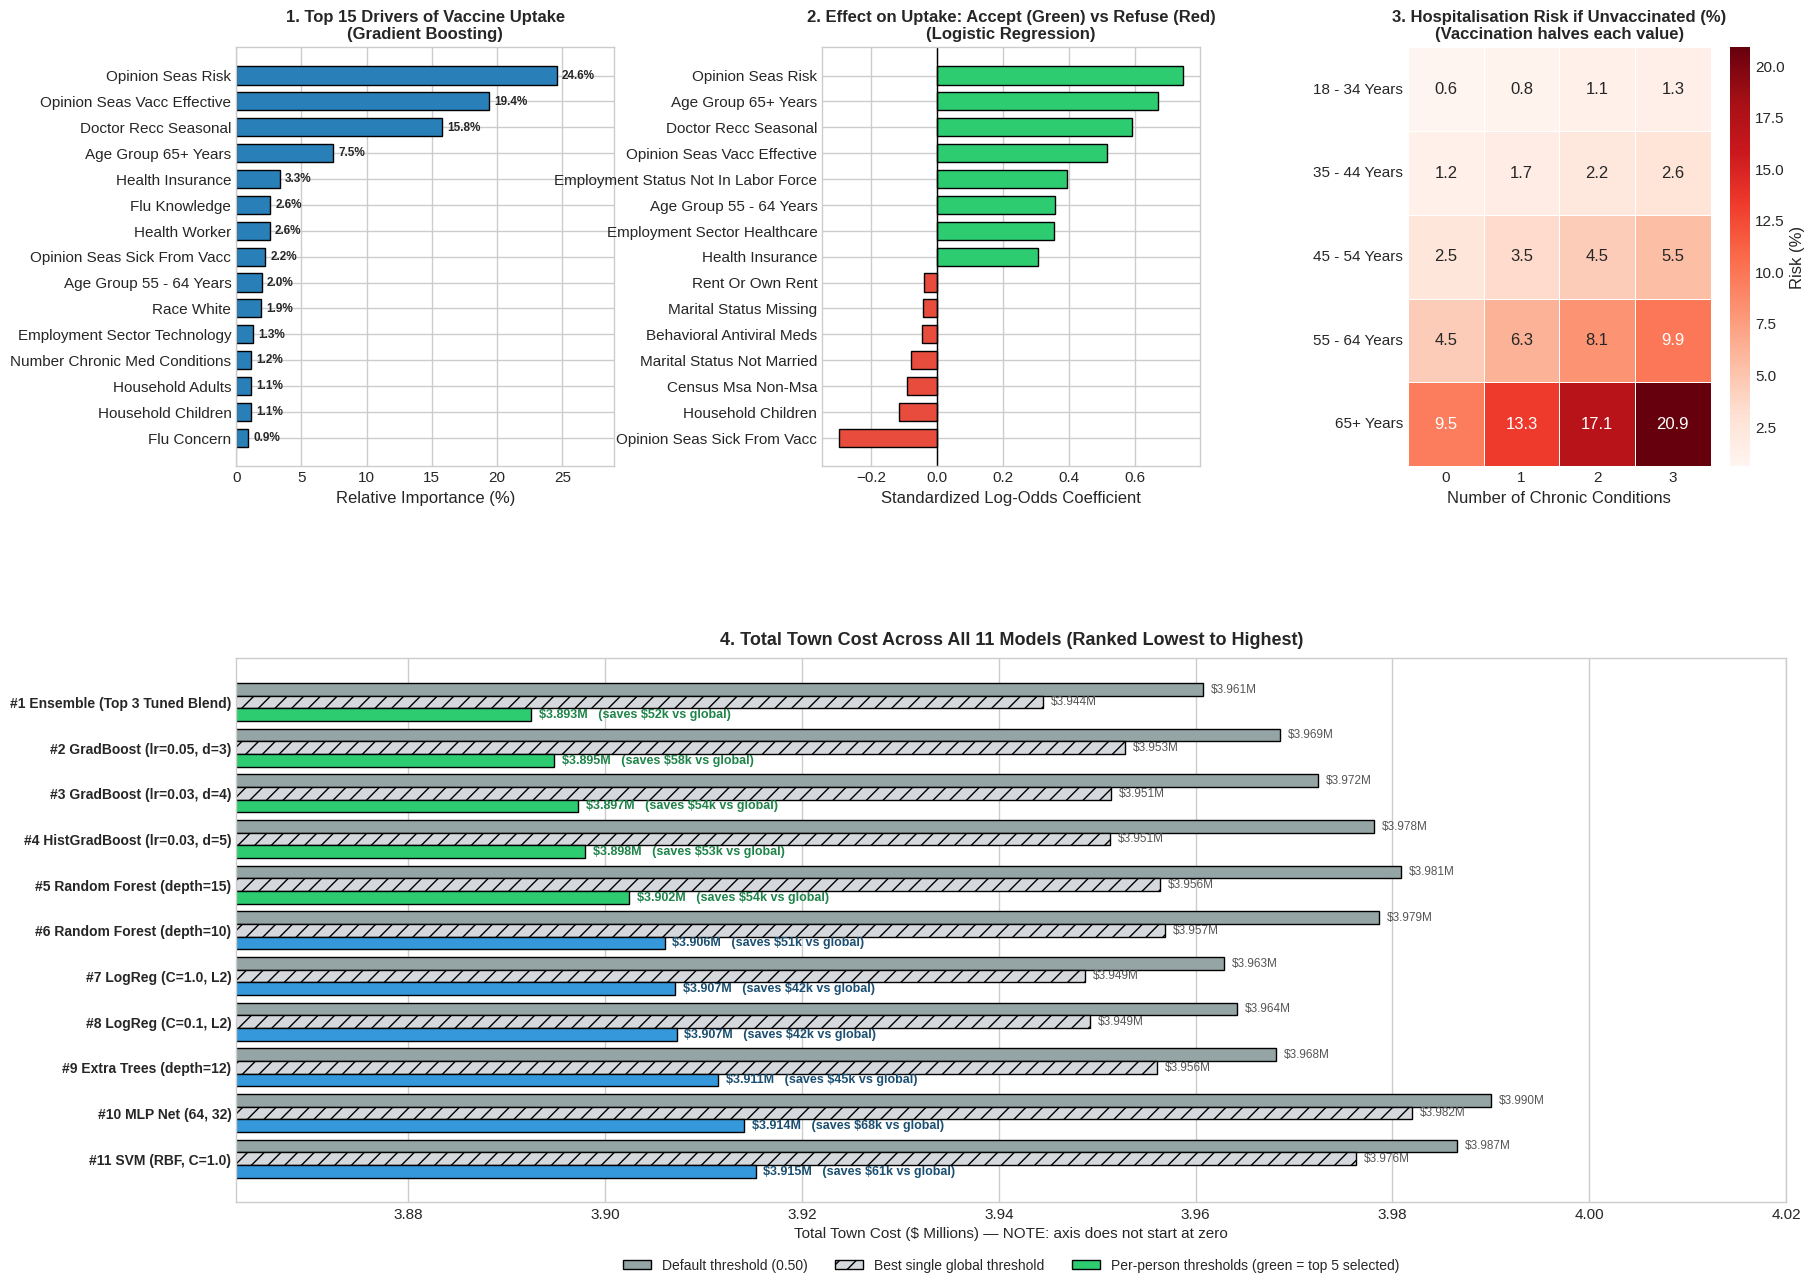

In [20]:
plt.style.use('seaborn-v0_8-whitegrid')
fig = plt.figure(figsize=(20, 15))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.3], hspace=0.4, wspace=0.55)

# -------------------------------------------------------------
# PLOT 1: TOP 15 COLUMNS DRIVING VACCINE UPTAKE (GRADIENT BOOSTING)
# -------------------------------------------------------------
ax1 = fig.add_subplot(gs[0, 0])

gb_model = candidate_models['GradBoost (lr=0.05, d=3)']
gb_model.fit(X_train_encoded, y_train)

feat_imp = pd.Series(gb_model.feature_importances_, index=X_train_encoded.columns)
top_15_imp = feat_imp.nlargest(15).sort_values(ascending=True)
clean_names = [n.replace('_', ' ').title() for n in top_15_imp.index]

bars1 = ax1.barh(clean_names, top_15_imp.values * 100, color='#2980b9', edgecolor='black', height=0.7)
ax1.set_title('1. Top 15 Drivers of Vaccine Uptake\n(Gradient Boosting)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Relative Importance (%)')
for bar in bars1:
    w = bar.get_width()
    ax1.text(w + 0.4, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=8.5, fontweight='bold')
ax1.set_xlim(0, top_15_imp.max() * 100 * 1.18)

# -------------------------------------------------------------
# PLOT 2: DIRECTION OF EFFECT ON UPTAKE (LOGISTIC REGRESSION)
# -------------------------------------------------------------
ax2 = fig.add_subplot(gs[0, 1])

lr_pipe = candidate_models['LogReg (C=1.0, L2)']
lr_pipe.fit(X_train_encoded, y_train)
coefs = pd.Series(lr_pipe.named_steps['logisticregression'].coef_[0], index=X_train_encoded.columns)

top_coefs = pd.concat([coefs.nsmallest(7), coefs.nlargest(8)]).sort_values()
clean_coef_names = [n.replace('_', ' ').title() for n in top_coefs.index]
colors2 = ['#e74c3c' if c < 0 else '#2ecc71' for c in top_coefs.values]

ax2.barh(clean_coef_names, top_coefs.values, color=colors2, edgecolor='black', height=0.7)
ax2.axvline(0, color='black', linewidth=1)
ax2.set_title('2. Effect on Uptake: Accept (Green) vs Refuse (Red)\n(Logistic Regression)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Standardized Log-Odds Coefficient')

# -------------------------------------------------------------
# PLOT 3: HOSPITALISATION RISK BY AGE & CHRONIC CONDITIONS
# -------------------------------------------------------------
ax3 = fig.add_subplot(gs[0, 2])

age_order = ['18 - 34 Years', '35 - 44 Years', '45 - 54 Years', '55 - 64 Years', '65+ Years']
chronic_levels = [0, 1, 2, 3]
risk_grid = pd.DataFrame(
    {c: estimate_hospitalisation_prob(pd.Series(age_order), pd.Series([c] * len(age_order)), False) * 100
     for c in chronic_levels},
    index=age_order
)
sns.heatmap(risk_grid, annot=True, fmt='.1f', cmap='Reds', cbar_kws={'label': 'Risk (%)'},
            linewidths=0.5, ax=ax3)
ax3.set_title('3. Hospitalisation Risk if Unvaccinated (%)\n(Vaccination halves each value)', fontsize=12, fontweight='bold')
ax3.set_xlabel('Number of Chronic Conditions')
ax3.set_ylabel('')

# -------------------------------------------------------------
# PLOT 4: ALL 11 MODELS — TOWN COST
# -------------------------------------------------------------
ax4 = fig.add_subplot(gs[1, :])

plot_df = cost_leaderboard.sort_values(by='Min Total Cost ($)', ascending=True).reset_index(drop=True)
models_list = [f"#{i+1} {m}" for i, m in enumerate(plot_df['Model'])]
min_costs = plot_df['Min Total Cost ($)'] / 1e6
cost_05 = plot_df['Cost @ 0.50 ($)'] / 1e6
cost_glb = plot_df['Cost @ best global th ($)'] / 1e6

y = np.arange(len(models_list)) * 1.3      # extra spacing between models
h = 0.36
ax4.barh(y - h, cost_05, h, label='Default threshold (0.50)', color='#95a5a6', edgecolor='black')
ax4.barh(y, cost_glb, h, label='Best single global threshold', color='#d5d8dc', edgecolor='black', hatch='//')
opt_colors = ['#2ecc71' if i < 5 else '#3498db' for i in range(len(models_list))]
ax4.barh(y + h, min_costs, h, color=opt_colors, edgecolor='black',
         label='Per-person thresholds (green = top 5 selected)')

for i in range(len(models_list)):
    ax4.text(cost_05.iloc[i] + 0.0008, y[i] - h, f"\\${cost_05.iloc[i]:.3f}M",
             va='center', fontsize=8.5, color='#555555')
    ax4.text(cost_glb.iloc[i] + 0.0008, y[i], f"\\${cost_glb.iloc[i]:.3f}M",
             va='center', fontsize=8.5, color='#555555')
    saving = (cost_glb.iloc[i] - min_costs.iloc[i]) * 1e3
    ax4.text(min_costs.iloc[i] + 0.0008, y[i] + h,
             f"\\${min_costs.iloc[i]:.3f}M   (saves \\${saving:.0f}k vs global)",
             va='center', fontsize=9, fontweight='bold',
             color='#1e8449' if i < 5 else '#1b4f72')

ax4.set_yticks(y)
ax4.set_yticklabels(models_list, fontsize=10, fontweight='bold')
ax4.invert_yaxis()
ax4.grid(axis='y', visible=False)
ax4.set_xlim(min(min_costs.min(), cost_05.min()) - 0.03, max(cost_05.max(), cost_glb.max()) + 0.03)
ax4.set_xlabel('Total Town Cost ($ Millions) — NOTE: axis does not start at zero', fontsize=11)
ax4.set_title('4. Total Town Cost Across All 11 Models (Ranked Lowest to Highest)',
              fontsize=13, fontweight='bold', pad=10)
ax4.legend(fontsize=10, loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)

plt.show()

### Step 5: Submission of Results

In [22]:
# -------------------------------------------------------------
# 1. GENERATE TOP 5 SUBMISSION CSV FILES (PER-PERSON THRESHOLDS)
# -------------------------------------------------------------
group_letter = "F"
submission_summary = []
saved_filenames = []

print("="*85)
print(f"STEP 5: GENERATING & VALIDATING FINAL 5 SUBMISSIONS (GROUP {group_letter})")
print("="*85)

for order_idx, model_name in enumerate(top_5_cost_models, start=1):
    # Per-person cost-optimal thresholds (computed in Step 4 from age & chronic conditions)
    test_probabilities = test_preds[model_name]
    test_binary_predictions = (test_probabilities >= test_thr).astype(int)

    # Build exact 2-column dataframe matching the example submission
    sub_df = pd.DataFrame({
        'respondent_id': test['respondent_id'].astype(int),
        'seasonal_vaccine': test_binary_predictions
    })

    # Strict verification checks (4749 rows, 2 columns, no nulls, only 0 or 1, ids match test)
    assert sub_df.shape == (4749, 2), f"Shape error in Order {order_idx}: {sub_df.shape}"
    assert list(sub_df.columns) == ['respondent_id', 'seasonal_vaccine'], "Column header mismatch!"
    assert sub_df.isnull().sum().sum() == 0, "Null values detected in submission!"
    assert set(sub_df['seasonal_vaccine'].unique()).issubset({0, 1}), "Invalid target values!"
    assert (sub_df['respondent_id'].values == example_sub['respondent_id'].values).all(), "IDs differ from example submission!"

    # Save CSV with official naming convention (index=False prevents extra unnamed column)
    filename = f"challenge_submission_group_{group_letter}_order_{order_idx}.csv"
    sub_df.to_csv(filename, index=False)
    saved_filenames.append(filename)

    vax_sent = int(sub_df['seasonal_vaccine'].sum())
    vax_pct = (vax_sent / len(sub_df)) * 100

    submission_summary.append({
        'Order': f"Order {order_idx}",
        'Filename': filename,
        'Model': model_name,
        'Threshold': 'per-person',
        'Rows': len(sub_df),
        'Vaccines Sent (1s)': f"{vax_sent} ({vax_pct:.1f}%)",
        'No Vaccine (0s)': f"{len(sub_df) - vax_sent} ({100 - vax_pct:.1f}%)"
    })

sub_summary_df = pd.DataFrame(submission_summary)
print(sub_summary_df.to_string(index=False))

# -------------------------------------------------------------
# 2. VERIFY EXACT CSV FORMAT MATCHES EXAMPLE
# -------------------------------------------------------------
print("\n" + "="*85)
print(f"RAW CSV FORMAT CHECK ({saved_filenames[0]}):")
print("="*85)
with open(saved_filenames[0], 'r') as f:
    for _ in range(6):
        print(f.readline().strip())

# -------------------------------------------------------------
# 3. DOWNLOAD FILES TO YOUR COMPUTER
# -------------------------------------------------------------
zip_filename = f"Group_{group_letter}_All_5_Submissions.zip"
with zipfile.ZipFile(zip_filename, 'w') as zf:
    for fname in saved_filenames:
        zf.write(fname)

files.download(zip_filename)

STEP 5: GENERATING & VALIDATING FINAL 5 SUBMISSIONS (GROUP F)
  Order                                 Filename                        Model  Threshold  Rows Vaccines Sent (1s) No Vaccine (0s)
Order 1 challenge_submission_group_F_order_1.csv Ensemble (Top 3 Tuned Blend) per-person  4749       2644 (55.7%)    2105 (44.3%)
Order 2 challenge_submission_group_F_order_2.csv     GradBoost (lr=0.05, d=3) per-person  4749       2658 (56.0%)    2091 (44.0%)
Order 3 challenge_submission_group_F_order_3.csv     GradBoost (lr=0.03, d=4) per-person  4749       2653 (55.9%)    2096 (44.1%)
Order 4 challenge_submission_group_F_order_4.csv HistGradBoost (lr=0.03, d=5) per-person  4749       2647 (55.7%)    2102 (44.3%)
Order 5 challenge_submission_group_F_order_5.csv     Random Forest (depth=15) per-person  4749       2639 (55.6%)    2110 (44.4%)

RAW CSV FORMAT CHECK (challenge_submission_group_F_order_1.csv):
respondent_id,seasonal_vaccine
4757,1
4758,1
4759,1
4760,1
4761,0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>